In [1]:
#| include: false
%load_ext autoreload
%autoreload 2


In [ ]:
#| include: false
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

from miia_pec1.plot import plot_image, plot_histogram

from pathlib import Path

# Configuración de tamaño de las figuras por defecto para que no se vaya de madre en quarto
plt.rcParams["figure.figsize"] = (5, 3)

In [3]:
#| include: false
DATA_DIR =  Path.cwd() / "data" / "DibujosNPT"

## Ejercicio 1.1

La aplicación **image-playground** para realizar procesamiento de imágenes se encuentra desplegada en huggingface [@huggingface]:
[https://huggingface.co/spaces/vichel0creg0/image-playground](https://huggingface.co/spaces/vichel0creg0/image-playground).

También puede ejecutarse de forma local utilizando el comando:

In [ ]:
#| output: false
# Lanza la interfaz UI de la aplicación image-playground de forma local
!uv run miia-pec1 ui --port 5432

## Ejercicio 1.2

Para reducir el ruido, se ha diseñado un pipeline de cuatro etapas.

```{mermaid}
%%| fig-width: 6
%%| label: fig-exercise-1-2-1
%%| fig-cap: "Pipeline de eliminación de ruido"
flowchart LR
    A["Umbralización inversa"]
    B["Filtro patrones de píxeles conectados pequeños"]
    C["Dilatación"]
    D["Inversión"]

    A --> B
    B --> C
    C --> D
```

In [5]:
#| include: false
EXAMPLES = [f for f in DATA_DIR.iterdir() if f.name.startswith(("N_307", "N_328"))]

En la @fig-exercise-1-2-pipeline-1 se muestra la primera etapa del pipeline, consiste en una umbralización binaria inversa. Esta operación permite eliminar tonalidades de grin intermedias y obtener una representación binaria en la que los trazos de los dibujos aparecen en blanco y el fondo en negro.

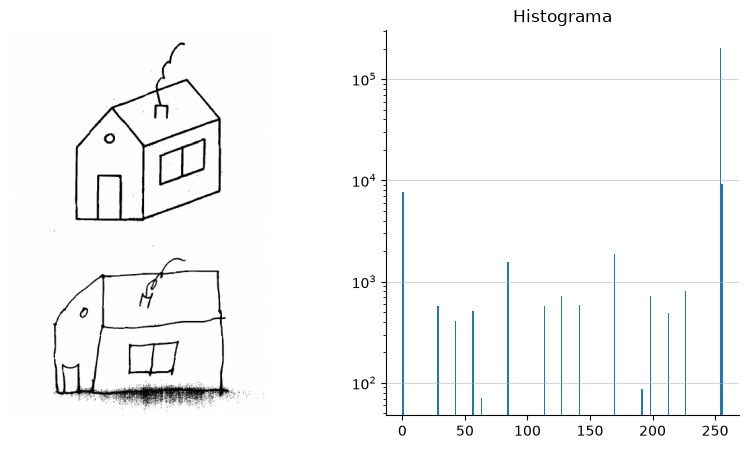

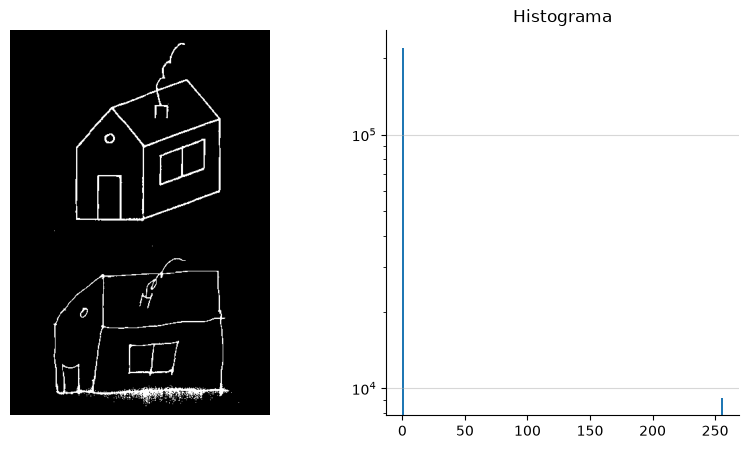

In [6]:
#| echo: false
#| label: fig-exercise-1-2-pipeline-1
#| fig-cap: "Primer paso del pipeline: Umbralización inversa"
#| fig-subcap:
#|  - "Imagen original y su histograma"
#|  - "Imagen binarizada y su histograma"
#| layout-ncol: 2
img = cv.imread(str(DATA_DIR / "N_328_THS_TOTAL-ev1-h.png"), cv.IMREAD_GRAYSCALE)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
plot_image(img, ax=ax1)
plot_histogram(img, ax=ax2, scale="log", title="Histograma")
plt.show()


_, img = cv.threshold(img, 75, 255, cv.THRESH_BINARY_INV)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
plot_image(img, ax=ax1)
plot_histogram(img, ax=ax2, scale="log", title="Histograma")
plt.show()

In [7]:
#| include: false
def plot_connected_pixel(labels, stats, centroids, *, ax=None,indices=None):
    """
    Dibuja las regiones conectadas de una imagen etiquetada.

    Parámetros:
    ===========
    labels: matriz de etiquetas de la imagen
    stats: estadísticas de las regiones conectadas
    centroids: centroides de las regiones conectadas

    ax: eje de Matplotlib donde se dibujará la imagen (opcional)
    indices: índices de las regiones a dibujar (opcional)

    Returns:
    ========
    ax: Eje de Matplotlib con la imagen dibujada
    """
    if ax is None:
        fig, ax = plt.subplots()


    n = len(stats)

    rng = np.random.default_rng(12)
    colors = rng.random((n, 3))

    # Dibujo de las regiones conectadas
    ax.imshow(labels)

    # Se dibujan los contornos de cada región y su centroide
    # escalado según el tamaño de la región
    areas = stats[:, cv.CC_STAT_AREA]
    sizes = np.interp(areas, (areas.min(), areas.max()), (50, 300))

    # El 1 omite la etiqueta de fondo (0) en las regiones conectadas
    indices = indices if indices is not None else range(1, n)
    for i in indices:
        mask = np.uint8(labels == i)

        # Se recupera todos los contornos de la región
        contours, _ = cv.findContours(mask, cv.RETR_TREE, cv.CHAIN_APPROX_SIMPLE)

        for contour in contours:
            # Se pisa el contorno para tener un único color por región
            ax.plot(contour[:, 0, 0], contour[:, 0, 1], color=colors[i], lw=2)

        ax.scatter(*centroids[i], s=sizes[i], color=colors[i], edgecolor='black')

    ax.axis("off")
    ax.set_title(f"Regiones conectadas ({len(indices)})")

    return ax


def filter_connected_pixels(n, labels, stats, *, min_area=50):
    """
    Filtra las regiones conectadas de una imagen etiquetada según un área mínima.

    Parámetros:
    ===========
    n: número de regiones conectadas
    labels: matriz de etiquetas de la imagen
    stats: estadísticas de las regiones conectadas

    min_area: área mínima para conservar una región (opcional, por defecto 50)

    Returns:
    ========
    clean_img: Imagen binaria con las regiones pequeñas eliminadas
    clean_labels: Matriz de etiquetas con las regiones pequeñas eliminadas
    indices: Índices de las regiones eliminadas
    """
    clean_img = np.zeros_like(labels, dtype=np.uint8)
    clean_labels = np.zeros_like(labels, dtype=np.uint8)
    indices = []

    for i in range(1, n):
        if stats[i, cv.CC_STAT_AREA] >= min_area:
            clean_img[labels == i] = 255
            clean_labels[labels == i] = i
            indices.append(i)

    return clean_img, clean_labels, indices

Para loa segunda etapa del pipeline se utiliza el procedimiento propuesto por Moracho [@moracho2018contornos], que se basa en el filtrado de los componentes conectados según su área.

En la @fig-exercise-1-2-pipeline-2 se muestra como el número de componentes conectados se reduce de 83 a 9, eliminando gran parte de las pequeñas regiones asociadas al ruido.

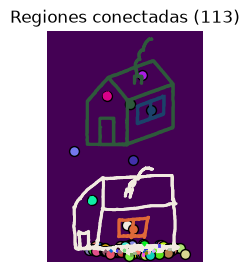

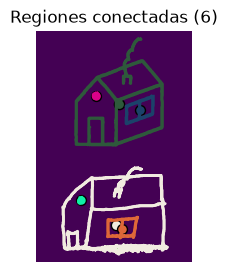

In [9]:
#| echo: false
#| label: fig-exercise-1-2-pipeline-2
#| fig-cap: "Componentes conectadas"
#| fig-subcap:
#|  - "Antes del filtrado"
#|  - "Después del filtrado"
#| layout-ncol: 2
#| fig-width: 2
#| fig-height: 1
#| fig-align: center
n, labels, stats, centroids = cv.connectedComponentsWithStats(img, connectivity=8)
plot_connected_pixel(labels, stats, centroids)

clean_img, clean_labels, indices = filter_connected_pixels(n, labels, stats, min_area=40)
plot_connected_pixel(clean_labels, stats, centroids, indices=indices)
plt.show()

Finalmente, @fig-exercise-1-2-pipeline-3, se aplica una dilatación morfológica para aumentar ligeramente el grosor de la los trazos y reforzar las líneas que hayan quedado demasiado finas tras las etapas anteriores.

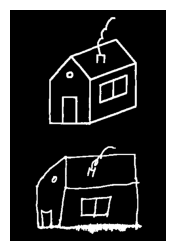

In [10]:
#| echo: false
#| label: fig-exercise-1-2-pipeline-3
#| fig-cap: "Dilatación morfológica, engrosamiento de los trazos de la imagen"
#| out-width: 50%
kernel = np.ones((3, 3),dtype=np.uint8)
img = cv.dilate(clean_img, kernel, iterations=1)

plot_image(img)
plt.show()

In [11]:
#| include: false
def pipeline_clean_noise(img, *, thresh=127, min_area=40, kernel_size=3, connectivity=8):
    """
    Pipeline para filtrar ruido en una imagen binaria.

    Parámetros:
    ===========
    img: Imagen de entrada en escala de grises

    thresh: Umbral para binarización inversa
    min_area: Área mínima de las regiones conectadas a conservar
    kernel_size: Tamaño del kernel para la dilatación
    connectivity: Conectividad para la detección de componentes conectadas

    Returns:
    ========
    list: Lista de imágenes intermedias y finales [img_1, img_2, img_3, img_4]
    """
    _, img_1 = cv.threshold(img, thresh, 255, cv.THRESH_BINARY_INV)

    n, labels, stats, centroids = cv.connectedComponentsWithStats(img_1, connectivity=connectivity)
    img_2, *_ = filter_connected_pixels(n, labels, stats, min_area=min_area)

    kernel = np.ones((kernel_size, kernel_size), dtype=np.uint8)
    img_3 = cv.dilate(img_2, kernel, iterations=1)

    img_4 = cv.bitwise_not(img_3)

    return [img_1, img_2, img_3, img_4]

En la @fig-exercise-1-2-pipeline-end, se presenta una comparación de las imágenes de entrada con los resultados obtenidos en cada etapa de pipeline.

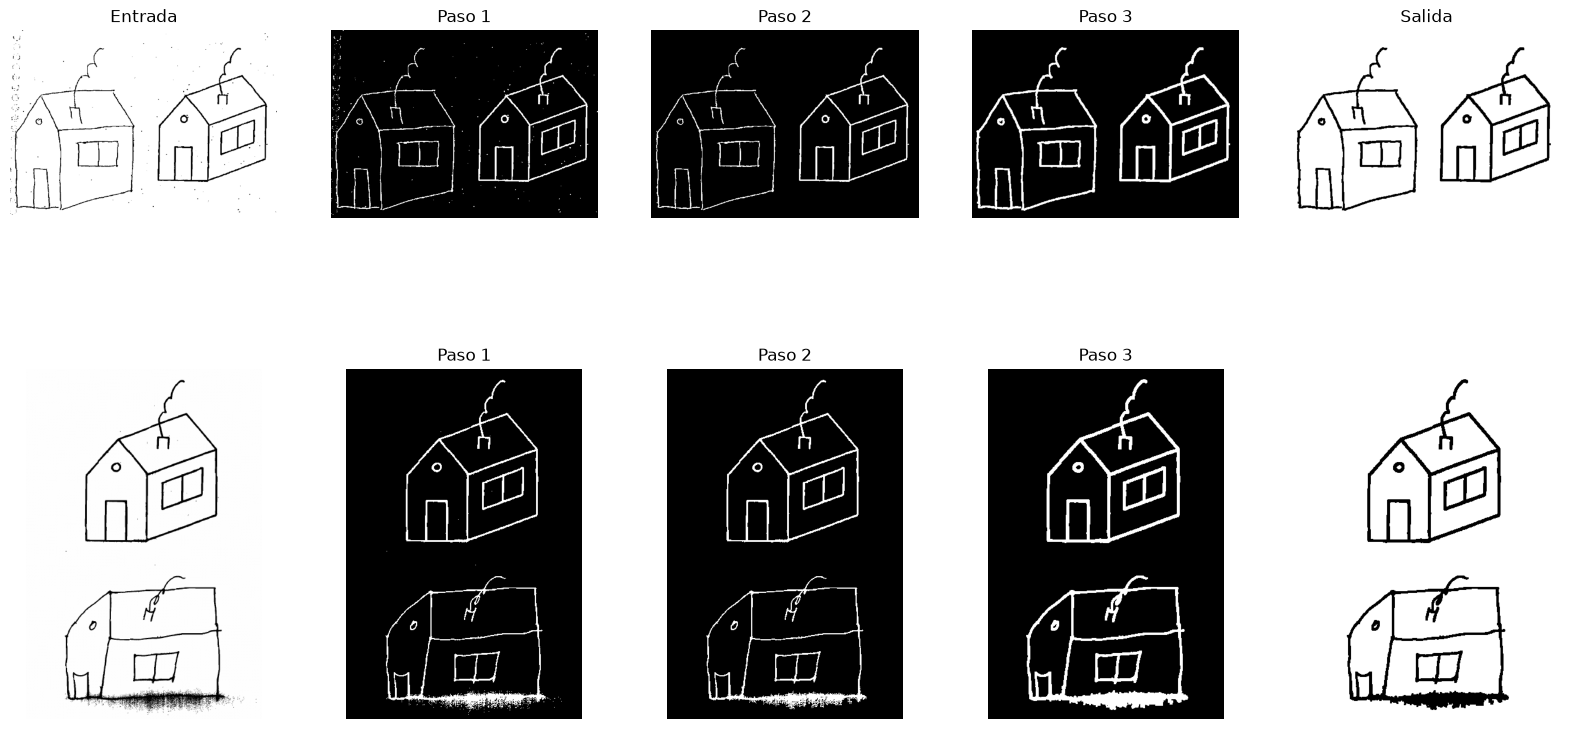

In [12]:
#| echo: false
#| label: fig-exercise-1-2-pipeline-end
#| fig-cap: "Estapas del pipeline de filtrado de ruído"
#| out-width: 50%
fig, ax = plt.subplots(2, 5, figsize=(20, 10))


for i, example in enumerate(EXAMPLES):
    img = cv.imread(example, cv.IMREAD_GRAYSCALE)
    plot_image(img, ax=ax[i, 0], title="Entrada" if i == 0 else "")

    for j, img_out in enumerate(pipeline_clean_noise(img), 1):
        plot_image(img_out, ax=ax[i, j], title=f"Paso {j}" if j <4 else "Salida" if i == 0 else "")